# 06 · Sensitivity of the results to the analysis choices

**Question.**  Every number in notebooks 03-05 rests on choices: which
epochs, how the flux is normalised, which star/galaxy infill, the PSF model,
how the cloud region and the windows are drawn, the fit range and weighting,
the jackknife, how collapsed fits are treated, and the S2 estimator.  Do the
claims depend on them?

**How.**  One choice at a time is changed from the paper analysis
(`Config()`), everything downstream is redone with it -- the sample, the
per-window fits, the matching PSF injection calibration, the population
statistics and the region measurements -- and every claim is re-evaluated.
The choices are listed in `mabsf.sensitivity.CHOICES`; the claims and their
tests in `mabsf.sensitivity.RULES` (claim numbers as in
`docs/claims_inventory.md`).

What each claim can depend on:
* C1-C4 (Regions 1 and 2) use only the deconvolved region cubes, so only the
  PSF width (D5) and gain cap (D6) change them;
* C5 (Region 1 untrackable, Region 2 trackable) uses only the structure maps,
  so none of these choices changes it;
* C6 depends on the sample, the fitted inclinations and the deconvolution;
* C7-C13 depend on everything else.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mabsf import config as C, data as D, fitting as F, sensitivity as SE, shape as S, plotting
from mabsf.checks import check, targets

plotting.style()
RECOMPUTE = False     # True: refit every choice (~1 h on 8 cores) and re-evaluate the claims (~10 min)
path = D.results('sensitivity_claims.csv')
if RECOMPUTE:
    SE.fit_choices(procs=8)
if RECOMPUTE or not os.path.exists(path):
    SE.run()
T = pd.read_csv(path)
pd.DataFrame(SE.CHOICES, columns=['group', 'choice', 'change from Config()']).set_index('group')

,choice,change from Config()
group,,
base,paper analysis,{}
D1,epochs 1-5 only,"{'epochs': (0, 1, 2, 3, 4)}"
D1,drop epoch 1,"{'epochs': (1, 2, 3, 4, 5, 6)}"
D1,drop epoch 5,"{'epochs': (0, 1, 2, 3, 5, 6)}"
D1,drop epoch 7,"{'epochs': (0, 1, 2, 3, 4, 5)}"
D2,no normalisation (raw flux),{'norm': 'none'}
D2,one cloud-wide factor per epoch,{'norm': 'global'}
D3,infill draw 2,{'infill': 'draw2'}
D3,infill draw 3,{'infill': 'draw3'}


## 1. All claims under all choices

Each row is one choice, each column one claim.  **Green / red**: the claim's
test (below) passes / fails.  **Blue**: a value without a pass/fail test,
shaded by its change from the paper analysis (top row); full shade at the
tolerance listed in `mabsf.sensitivity.MATRIX` (0.06 in f, 0.05-0.06 in an
axis ratio, 8 deg, 2 windows).

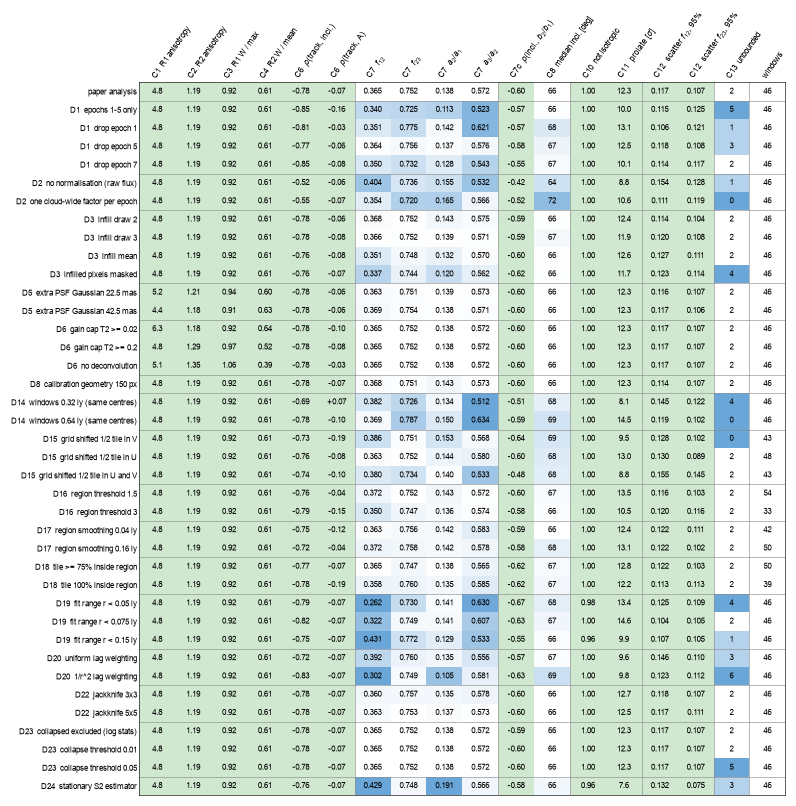

In [2]:
fig, ax = plt.subplots(figsize=(plotting.W_IN, 0.155 * len(T) + 1.3))
SE.plot_matrix(T, ax)
fig.tight_layout()
fig.savefig(D.figures('sensitivity_matrix.pdf'), bbox_inches='tight')
fig.savefig(D.figures('sensitivity_matrix.png'), dpi=250, bbox_inches='tight')

**The claims.**  Each column of the matrix is one quantity behind a claim of the
paper (numbering as in `docs/claims_inventory.md`).  The table says what the
claim is, how the quantity is measured, and the condition the matrix colours
green or red; quantities marked '-' are values without a pass/fail test (the
common shape, the orientations, the count of unbounded windows), whose
change is shaded blue instead.  The last columns give the value in the paper
analysis and its range over all the choices.  C5 (Region 1 cannot be
followed between epochs, Region 2 can) is not listed: it uses only the
structure maps, which none of these choices changes.

In [3]:
SE.claims_table(T).reset_index().style.hide(axis='index').format(precision=3).set_properties(
    subset=['what the paper claims', 'quantity measured'],
    **{'white-space': 'normal', 'text-align': 'left', 'min-width': '18em'})

claim,what the paper claims,quantity measured,passes if,paper value,range over choices,computed in
C1 R1 anisotropy,Region 1 is strongly anisotropic in the sky plane: its structure is filamentary.,"Ratio of the largest to the smallest PSF-deconvolved in-plane S2 among 9 direction wedges, at separations 0.02-0.03 ly; the minimum of that ratio over the separations is tested.",ratio > 3,4.758,4.36 - 6.3,notebook 04
C2 R2 anisotropy,Region 2 is nearly isotropic in the sky plane: a compact clump.,The same largest/smallest wedge ratio for Region 2 (in its co-moving window); the maximum over 0.02-0.03 ly is tested.,ratio < 1.5,1.191,1.18 - 1.35,notebook 04
C3 R1 W / max,"In Region 1, brightness changes along the depth direction W about as much as along the most variable in-plane direction (the filaments are steep in depth).",Median over the W points of S2 along W divided by the largest wedge S2 at the same separation.,0.5 < ratio < 1.5,0.924,0.905 - 1.06,notebook 04
C4 R2 W / mean,"In Region 2, followed in its co-moving window, brightness varies less along W than in the sky plane: the clump persists in depth.",Median over the W points of S2 along W divided by the mean wedge S2 at the same separation.,ratio < 1,0.613,0.389 - 0.643,notebook 04
"C6 ρ(track, incl.)",How easily structure can be followed from epoch to epoch is set by its 3D orientation: structure whose long axis lies close to W is easy to track.,"Spearman correlation, over the windows, of trackability (mean epoch 2-4 correlation of the 0.01-0.1 ly structure, at the best shift) with the inclination of the fitted long axis from W.",rho < 0 and p < 0.01,-0.782,-0.85 - -0.523,notebook 04
"C6 ρ(track, A)",... and not by how isotropic the structure looks on the sky.,Spearman correlation of trackability with the sky-plane anisotropy A of each window.,|rho| < 0.3,-0.074,-0.188 - 0.0704,notebook 04
C7 f12,"The windows share a common, elongated shape.","Common value (maximum likelihood with intrinsic scatter) of f12 = S2(long axis) / S2(middle axis) at the same separation, below 0.1 ly; 1 = no elongation.",-,0.365,0.262 - 0.431,notebook 03
C7 f23,The common shape is also flattened.,Common value of f23 = S2(middle axis) / S2(short axis); 1 = no flattening.,-,0.752,0.72 - 0.787,notebook 03
C7 a2/a1,"The common shape in axis-ratio terms, a1 : a2 : a3 ~ 13 : 2 : 1.",Common f12 converted to a correlation-length ratio at the median slope alpha: a2/a1 = f12^(1/alpha).,-,0.138,0.105 - 0.191,notebook 03
C7 a3/a2,(the second axis ratio of the common shape),"a3/a2 = f23^(1/alpha), at the median alpha.",-,0.572,0.512 - 0.634,notebook 03


## 2. How far each number moves

In [4]:
G = SE.grade(T)
rows = []
for col, short, desc, rule in SE.RULES:
    v = T[col]
    r = dict(claim=short, quantity=desc, paper=v.iloc[0], min=v.min(), max=v.max(),
             choice_min=T.choice[v.idxmin()], choice_max=T.choice[v.idxmax()])
    if col in G:
        r['fails'] = ', '.join(T.choice[~G[col].astype(bool)]) or '-'
    rows.append(r)
R = pd.DataFrame(rows).set_index('claim')
R.round(3)

,quantity,paper,min,max,choice_min,choice_max,fails
claim,,,,,,,
C1,R1 in-plane anisotropy (min over 0.02-0.03 ly)...,4.758,4.363,6.302,extra PSF Gaussian 42.5 mas,gain cap T2 >= 0.02,-
C2,R2 in-plane anisotropy (max) < 1.5x,1.191,1.178,1.355,extra PSF Gaussian 42.5 mas,no deconvolution,-
C3,R1: W variation within 0.5-1.5x of the largest...,0.924,0.905,1.065,extra PSF Gaussian 42.5 mas,no deconvolution,-
C4,R2 (tracked): W variation below the in-plane mean,0.613,0.389,0.643,no deconvolution,gain cap T2 >= 0.02,-
C6,"trackability follows inclination (rho < 0, p <...",-0.782,-0.850,-0.523,epochs 1-5 only,no normalisation (raw flux),-
C6b,trackability does not follow sky-plane anisotr...,-0.074,-0.188,0.070,tile 100% inside region,windows 0.32 ly (same centres),-
C7,common f12 (elongation),0.365,0.262,0.431,fit range r < 0.05 ly,fit range r < 0.15 ly,NaN
C7,common f23 (flattening),0.752,0.720,0.787,one cloud-wide factor per epoch,windows 0.64 ly (same centres),NaN
C7,common a2/a1,0.138,0.105,0.191,1/r^2 lag weighting,stationary S2 estimator,NaN


**Reading the matrix.**
* Every pass/fail test holds under every choice (all green).
* C1-C6 are insensitive: only the deconvolution settings change C1-C4, and
  none enough to change the conclusion.
* **f12 depends on the fit range (D19, 0.26-0.43) and the lag weighting (D20),
  but the common axis ratio a2/a1 does not (0.13-0.14 across D19).**  Both
  choices change the slope alpha (0.41-0.68 across D19), and f12 = (a2/a1)^alpha
  follows alpha; the shape itself is stable.  This is why the shape is stated
  as axis ratios, and f12 and f23 are used for the statistics.
* a3/a2 moves most with the window size (D14, 0.51-0.63) and the fit range
  (0.53-0.63): the estimator is biased low as the fitted scales grow (see the
  window-size test), so the flattening is the less certain of the two ratios.
* The number of unbounded windows (C13) ranges from 0 to 6: it is a property
  of the fit threshold, not a robust count.

## 3. The S2 estimator (D24)

The last row is the analysis as first submitted: the stationary S2
estimator (notebook 03, section 7).  It gives the least elongated common
shape of all the choices (a2/a1 = 0.19; every other choice gives 0.105-0.165),
because the fluctuation amplitude varies within the windows and only the
exact estimator handles that.  On stationary synthetic fields the two
estimators agree and the exact one is twice as precise; it is therefore the
default.

In [5]:
d24 = T[T.group.isin(['base', 'D24'])].set_index('choice')
d24[['n', 'n_collapsed', 'f12', 'sig_f12_95', 'f23', 'sig_f23_95', 'common_a2a1', 'common_a3a2',
     'median_alpha', 'median_incl', 'prolate_sigma', 'rho_incl_b2b1', 'C6_rho_incl']].T.round(3)

choice,paper analysis,stationary S2 estimator
n,46.000,46.000
n_collapsed,2.000,3.000
f12,0.365,0.429
sig_f12_95,0.117,0.132
f23,0.752,0.748
sig_f23_95,0.107,0.075
common_a2a1,0.138,0.191
common_a3a2,0.572,0.566
median_alpha,0.509,0.511
median_incl,66.402,65.734


## 4. Checks

* The first row reproduces notebook 03 (same configuration, same code).
* The D24 row reproduces the original analysis (values frozen in
  `validation/`, 'dedup' calibration): the estimator is the only difference.
* The C1-C4 values of the paper row reproduce the original regions analysis.

In [6]:
summ, k = S.summary(C.Config(), n_boot=300)
b = T.iloc[0]
for q in ('f12', 'f23', 'sig_f12_95', 'sig_f23_95'):
    check('paper row %s = notebook 03' % q, b[q], summ['variance_ratio'][q], rtol=1e-9)
check('paper row common shape = notebook 03', [b.common_a2a1, b.common_a3a2],
      [summ['common_a2a1'], summ['common_a3a2']], rtol=1e-9)
t = targets()['population_dedup']; fs = T[T.group == 'D24'].iloc[0]
for q in ('f12', 'f23', 'sig_f12', 'sig_f23'):
    check('D24 row %s = original analysis' % q, fs[q], t['variance_ratio'][q], rtol=1e-5)
check('D24 row common shape = original analysis', [fs.common_a2a1, fs.common_a3a2],
      [t['common_a2a1'], t['common_a3a2']], rtol=1e-6)
check('D24 row prolate sigma = original analysis', fs.prolate_sigma, t['claims']['C11_prolate_sigma'], rtol=1e-6)
check('D24 row median inclination = original analysis', fs.median_incl, t['claims']['C8_median_incl'], rtol=1e-6)
TR = targets()['region_claims']
check('paper row C1-C4 = original regions', [b.C1_aniso_min, b.C2_aniso_max, b.C3_w_over_max, b.C4_w_over_mean],
      [TR['R1']['aniso_min'], TR['R2']['aniso_max'], TR['R1']['w_over_max_median'], TR['R2']['w_over_mean_median']],
      rtol=1e-10)

ok   paper row f12 = notebook 03                      0.365327  (expected 0.365327)
ok   paper row f23 = notebook 03                      0.752428  (expected 0.752428)
ok   paper row sig_f12_95 = notebook 03               0.116653  (expected 0.116653)
ok   paper row sig_f23_95 = notebook 03               0.106612  (expected 0.106612)
ok   paper row common shape = notebook 03             [0.13849 0.57209]  (expected [0.13849 0.57209])
ok   D24 row f12 = original analysis                  0.428981  (expected 0.428981)
ok   D24 row f23 = original analysis                  0.748065  (expected 0.748065)
ok   D24 row sig_f12 = original analysis              0.0898738  (expected 0.0898738)
ok   D24 row sig_f23 = original analysis              0.0520975  (expected 0.0520975)
ok   D24 row common shape = original analysis         [0.19064 0.56642]  (expected [0.19064 0.56642])
ok   D24 row prolate sigma = original analysis        7.58557  (expected 7.58557)
ok   D24 row median inclination = orig